# 01 — Soát dữ liệu HAM10000 / ISIC 2018 Task 3

Mục đích: **nhìn tận mắt dữ liệu trước khi đụng tới mô hình.** Mọi con số ở đây đếm bằng code,
không lấy từ mô tả trên web.

Notebook trả lời năm câu hỏi:
1. File có đủ và khớp nhau không?
2. Bảy lớp phân bố thế nào — lệch tới đâu?
3. Bao nhiêu tổn thương thật, mỗi tổn thương bao nhiêu ảnh?
4. **Chia theo ảnh thì rò rỉ bao nhiêu?** — cả kiểu train/val lẫn kiểu chia cho máy trạm federated.
5. Tập test chính thức có trùng ảnh với tập train không?

Đầu ra: `ketqua/danh_muc.csv` — một dòng một ảnh, mọi notebook sau đọc file này.

In [1]:
import os, glob, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

GOC = Path(os.environ.get("HAM_GOC", Path.home() / "ham_fl" / "data"))
RA  = GOC.parent / "ketqua"; RA.mkdir(exist_ok=True)
LOP = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]
TEN_LOP = {"MEL": "u hắc tố (ác tính)", "NV": "nốt ruồi (lành)", "BCC": "ung thư biểu mô tế bào đáy",
           "AKIEC": "dày sừng quang hoá / Bowen", "BKL": "tổn thương sừng lành tính",
           "DF": "u xơ da", "VASC": "tổn thương mạch máu"}
print("Thư mục dữ liệu:", GOC, "| tồn tại:", GOC.exists())

Thư mục dữ liệu: /home/deep/ham_fl/data | tồn tại: True


## 1. File có đủ và khớp nhau không?

Mỗi tập (Training / Validation / Test) có một file CSV nhãn dạng one-hot: mỗi ảnh một dòng, bảy cột
lớp, đúng một cột bằng 1. Kiểm ba thứ: mỗi dòng đúng một nhãn, mỗi dòng có file ảnh, và không có
ảnh nào thừa ra mà không có nhãn.

In [2]:
def doc_tap(tap):
    f = sorted((GOC / f"ISIC2018_Task3_{tap}_GroundTruth").rglob("*.csv"))
    assert f, f"Không thấy CSV nhãn cho tập {tap}"
    df = pd.read_csv(f[0])
    tong = df[LOP].sum(axis=1)
    assert (tong == 1).all(), f"{tap}: có {int((tong != 1).sum())} dòng không đúng một nhãn"
    df["lop"] = df[LOP].idxmax(axis=1)
    df["nhan"] = df["lop"].map({l: i for i, l in enumerate(LOP)})
    anh = {p.stem: p for p in (GOC / f"ISIC2018_Task3_{tap}_Input").rglob("*.jpg")}
    df["duong_dan"] = df["image"].map(lambda s: str(anh.get(s, "")))
    thieu = (df["duong_dan"] == "").sum()
    thua = len(set(anh) - set(df["image"]))
    print(f"{tap:<11} {len(df):>6} dòng nhãn | {len(anh):>6} file ảnh | thiếu ảnh: {thieu} | ảnh thừa: {thua}")
    df["tap"] = tap.lower()
    return df[["image", "tap", "lop", "nhan", "duong_dan"]]

ds = pd.concat([doc_tap(t) for t in ("Training", "Validation", "Test")], ignore_index=True)
ds.head()

Training     10015 dòng nhãn |  10015 file ảnh | thiếu ảnh: 0 | ảnh thừa: 0
Validation     193 dòng nhãn |    193 file ảnh | thiếu ảnh: 0 | ảnh thừa: 0
Test          1512 dòng nhãn |   1512 file ảnh | thiếu ảnh: 0 | ảnh thừa: 0


,image,tap,lop,nhan,duong_dan
0,ISIC_0024306,training,NV,1,/home/deep/ham_fl/data/ISIC2018_Task3_Training...
1,ISIC_0024307,training,NV,1,/home/deep/ham_fl/data/ISIC2018_Task3_Training...
2,ISIC_0024308,training,NV,1,/home/deep/ham_fl/data/ISIC2018_Task3_Training...
3,ISIC_0024309,training,NV,1,/home/deep/ham_fl/data/ISIC2018_Task3_Training...
4,ISIC_0024310,training,MEL,0,/home/deep/ham_fl/data/ISIC2018_Task3_Training...


## 2. Bảy lớp phân bố thế nào?

Chỗ này quyết định chỉ số đánh giá. Nếu một lớp chiếm phần lớn, accuracy thường sẽ đẹp giả tạo —
mô hình chỉ cần đoán lớp đó là đạt điểm cao. Hai dòng cuối bảng cho thấy điều đó bằng số.

In [3]:
bang = pd.crosstab(ds["lop"], ds["tap"]).reindex(LOP)[["training", "validation", "test"]]
bang["% train"] = (100 * bang["training"] / bang["training"].sum()).round(1)
bang["tên"] = [TEN_LOP[l] for l in bang.index]
display(bang)

tr = ds[ds.tap == "training"]
ti_le_nv = (tr.lop == "NV").mean()
print(f"Mô hình 'đoán mọi thứ là NV':  accuracy = {ti_le_nv:.1%}   balanced accuracy = {1/7:.1%}")
print(f"Lớp lớn nhất / nhỏ nhất: {bang['training'].max()} / {bang['training'].min()} "
      f"= gấp {bang['training'].max() / bang['training'].min():.0f} lần")

tap,training,validation,test,% train,tên
lop,,,,,
MEL,1113,21,171,11.1,u hắc tố (ác tính)
NV,6705,123,909,66.9,nốt ruồi (lành)
BCC,514,15,93,5.1,ung thư biểu mô tế bào đáy
AKIEC,327,8,43,3.3,dày sừng quang hoá / Bowen
BKL,1099,22,217,11.0,tổn thương sừng lành tính
DF,115,1,44,1.1,u xơ da
VASC,142,3,35,1.4,tổn thương mạch máu


Mô hình 'đoán mọi thứ là NV':  accuracy = 66.9%   balanced accuracy = 14.3%
Lớp lớn nhất / nhỏ nhất: 6705 / 115 = gấp 58 lần


## 3. Bao nhiêu tổn thương thật?

HAM10000 chụp nhiều ảnh cho cùng một nốt trên da — khác góc, khác độ phóng đại. ISIC phát hành file
`LesionGroupings.csv` gắn mỗi ảnh với mã tổn thương. Đếm xem có bao nhiêu tổn thương thật và các
ảnh dồn cục tới đâu.

In [4]:
f = sorted(GOC.glob("*LesionGroupings*.csv"))
assert f, "Không thấy file LesionGroupings"
nhom = pd.read_csv(f[0])
print("Các cột trong file:", list(nhom.columns))
cot_anh = "image" if "image" in nhom.columns else nhom.columns[0]
cot_tt = next(c for c in nhom.columns if "lesion" in c.lower())
nhom = nhom.rename(columns={cot_anh: "image", cot_tt: "lesion_id"})
ds = ds.merge(nhom[["image", "lesion_id"]], on="image", how="left")

tr = ds[ds.tap == "training"]
print(f"Ảnh train không có mã tổn thương: {tr.lesion_id.isna().sum()}")
n_tt = tr.lesion_id.nunique()
moi = tr.groupby("lesion_id").size()
print(f"{len(tr)} ảnh train  ->  {n_tt} tổn thương thật  (trung bình {len(tr)/n_tt:.2f} ảnh / tổn thương)")
print(f"Tổn thương có >1 ảnh: {(moi > 1).sum()}  ({(moi > 1).mean():.1%})  —  "
      f"chứa {moi[moi > 1].sum()} ảnh ({moi[moi > 1].sum()/len(tr):.1%} số ảnh)")
print("Phân bố số ảnh mỗi tổn thương:", moi.value_counts().sort_index().to_dict())

# lớp nào dồn cục nhiều nhất?
theo_lop = tr.groupby("lop").agg(anh=("image", "size"), ton_thuong=("lesion_id", "nunique")).reindex(LOP)
theo_lop["ảnh/tổn thương"] = (theo_lop.anh / theo_lop.ton_thuong).round(2)
theo_lop

Các cột trong file: ['image', 'lesion_id', 'diagnosis_confirm_type']
Ảnh train không có mã tổn thương: 0
10015 ảnh train  ->  7470 tổn thương thật  (trung bình 1.34 ảnh / tổn thương)
Tổn thương có >1 ảnh: 1956  (26.2%)  —  chứa 4501 ảnh (44.9% số ảnh)
Phân bố số ảnh mỗi tổn thương: {1: 5514, 2: 1423, 3: 490, 4: 34, 5: 5, 6: 4}


,anh,ton_thuong,ảnh/tổn thương
lop,,,
MEL,1113,614,1.81
NV,6705,5403,1.24
BCC,514,327,1.57
AKIEC,327,228,1.43
BKL,1099,727,1.51
DF,115,73,1.58
VASC,142,98,1.45


## 4. Chia theo ảnh thì rò rỉ bao nhiêu?

Đây là con số quan trọng nhất của notebook. Mô phỏng hai kiểu chia mà các bài báo hay dùng:

**(a) Chia train/val 80/20 theo ảnh:** bao nhiêu ảnh val có "anh em" (ảnh cùng tổn thương) nằm trong
train? Nếu nhiều, điểm val là điểm của trí nhớ chứ không phải của khả năng tổng quát.

**(b) Chia cho 5 máy trạm federated theo ảnh:** bao nhiêu tổn thương bị xé ra nằm ở nhiều máy trạm?
Nếu nhiều, các "bệnh viện" giả lập đang chia nhau cùng một bệnh nhân — chúng giống nhau hơn bệnh
viện thật, và non-IID bị làm nhẹ đi một cách giả tạo.

Mỗi kiểu chạy 20 lần ngẫu nhiên để lấy trung bình, không dựa vào một lần bốc.

In [5]:
rng = np.random.default_rng(0)
tt = tr.lesion_id.values
a, b, b2 = [], [], []
nhieu_anh = set(tr.groupby("lesion_id").size().loc[lambda x: x > 1].index)
for _ in range(20):
    p = rng.permutation(len(tr)); cat = int(0.8 * len(tr))
    trong_train = set(tt[p[:cat]])
    a.append(np.mean([x in trong_train for x in tt[p[cat:]]]))
    may = rng.integers(0, 5, len(tr))
    so_may = pd.Series(may).groupby(tt).nunique()
    b.append((so_may > 1).mean())
    b2.append((so_may[so_may.index.isin(nhieu_anh)] > 1).mean())
print(f"(a) chia 80/20 theo ảnh: {np.mean(a):.1%} ảnh val có anh em trong train   (±{np.std(a):.1%})")
print(f"(b) chia 5 máy trạm theo ảnh: {np.mean(b):.1%} tổn thương bị xé ra nhiều máy trạm   (±{np.std(b):.1%})")
print(f"    — tính riêng tổn thương có >1 ảnh (loại có thể bị xé): {np.mean(b2):.1%}")
print("\nChia theo tổn thương thì cả hai con số trên bằng 0 theo định nghĩa.")

(a) chia 80/20 theo ảnh: 38.4% ảnh val có anh em trong train   (±0.8%)
(b) chia 5 máy trạm theo ảnh: 22.1% tổn thương bị xé ra nhiều máy trạm   (±0.2%)
    — tính riêng tổn thương có >1 ảnh (loại có thể bị xé): 84.4%

Chia theo tổn thương thì cả hai con số trên bằng 0 theo định nghĩa.


## 5. Kích thước ảnh

Đọc header của 300 ảnh (không giải nén cả ảnh, nên rất nhanh) để biết kích thước gốc — cần cho
quyết định resize về 224 hay 128.

In [6]:
mau = ds.sample(min(300, len(ds)), random_state=0)
kt = pd.Series([Image.open(p).size for p in mau.duong_dan]).value_counts()
print("Kích thước (rộng, cao) : số ảnh trong mẫu 300")
print(kt.head(8).to_string())

Kích thước (rộng, cao) : số ảnh trong mẫu 300
(600, 450)    300


## 6. Nhìn ảnh

Sáu ảnh ngẫu nhiên mỗi lớp. Để ý: nhiều lớp nhìn bằng mắt thường rất giống nhau — đó là lý do bài
toán khó, và là lý do bác sĩ da liễu cần máy soi da.

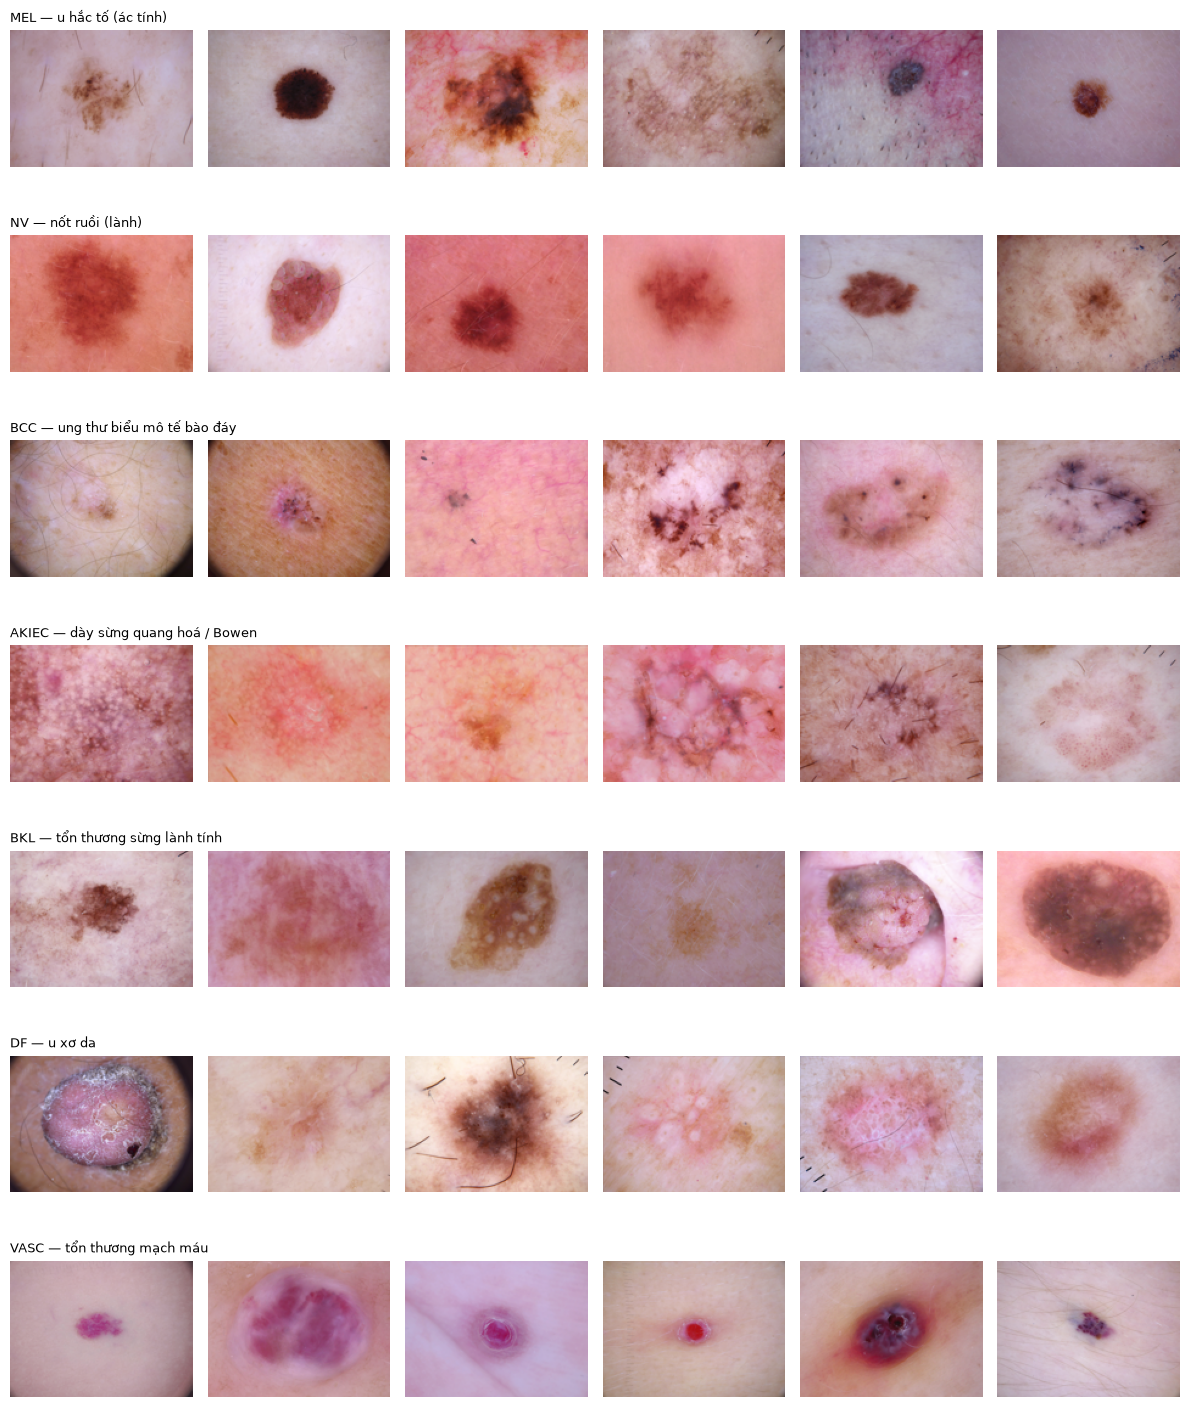

In [7]:
fig, ax = plt.subplots(len(LOP), 6, figsize=(12, 2.1 * len(LOP)))
for i, l in enumerate(LOP):
    m = tr[tr.lop == l].sample(min(6, (tr.lop == l).sum()), random_state=1)
    for j in range(6):
        ax[i, j].axis("off")
        if j < len(m):
            ax[i, j].imshow(Image.open(m.duong_dan.iloc[j]).resize((150, 112)))
    ax[i, 0].set_title(f"{l} — {TEN_LOP[l]}", loc="left", fontsize=9)
plt.tight_layout(); plt.savefig(RA / "anh_mau_theo_lop.png", dpi=110); plt.show()

## 7. Tập test chính thức có trùng ảnh với train không?

Nếu có, điểm trên tập test chính thức cũng bị thổi phồng, và cần biết trước khi so với bảng xếp hạng.
Dùng perceptual hash (pHash): thu mỗi ảnh về 32×32 xám, biến đổi DCT, giữ 8×8 hệ số tần số thấp, so với
trung vị thành 64 bit. Hai ảnh gần giống nhau có ít bit khác nhau. Ngưỡng ở đây **rất chặt** (≤ 4 bit)
để chỉ bắt ảnh gần như y hệt; các cặp tìm được hiện ra để nhìn bằng mắt, **không kết luận chỉ bằng số**.

Chạy mất vài phút cho khoảng 11.700 ảnh.

In [8]:
from scipy.fft import dct

def phash(p):
    with Image.open(p) as im:
        im.draft("L", (128, 128))
        a = np.asarray(im.convert("L").resize((32, 32), Image.LANCZOS), dtype=np.float64)
    d = dct(dct(a, axis=0, norm="ortho"), axis=1, norm="ortho")[:8, :8].flatten()
    return np.packbits(d > np.median(d[1:])).view(">u8")[0]

t0 = time.time()
ds["phash"] = [phash(p) for p in ds.duong_dan]
print(f"Băm {len(ds)} ảnh trong {time.time() - t0:.0f}s")

def dem_bit(x):
    x = x.astype(np.uint64); c = np.zeros(x.shape, np.int64)
    for _ in range(64):
        c += (x & np.uint64(1)).astype(np.int64); x >>= np.uint64(1)
    return c

H_tr = ds.loc[ds.tap == "training", "phash"].values.astype(np.uint64)
cap = []
for _, r in ds[ds.tap != "training"].iterrows():
    d = dem_bit(H_tr ^ np.uint64(r.phash))
    j = int(d.argmin())
    if d[j] <= 4:
        cap.append((r.tap, r.image, ds[ds.tap == "training"].image.iloc[j], int(d[j])))
cap = pd.DataFrame(cap, columns=["tap", "anh", "anh_train_gan_nhat", "khoang_cach_bit"])
print(f"Ảnh validation/test có ảnh train gần như y hệt (≤4 bit): {len(cap)}")
print(cap.groupby("tap").size().to_string() if len(cap) else "")
cap.head(10)

Băm 11720 ảnh trong 46s
Ảnh validation/test có ảnh train gần như y hệt (≤4 bit): 31
tap
test          30
validation     1


,tap,anh,anh_train_gan_nhat,khoang_cach_bit
0,validation,ISIC_0034511,ISIC_0028963,0
1,test,ISIC_0034619,ISIC_0029294,0
2,test,ISIC_0034639,ISIC_0028491,2
3,test,ISIC_0034722,ISIC_0025923,4
4,test,ISIC_0034747,ISIC_0027655,4
5,test,ISIC_0034758,ISIC_0031896,4
6,test,ISIC_0034786,ISIC_0031302,4
7,test,ISIC_0034818,ISIC_0026922,4
8,test,ISIC_0034872,ISIC_0033743,4
9,test,ISIC_0034885,ISIC_0029289,4


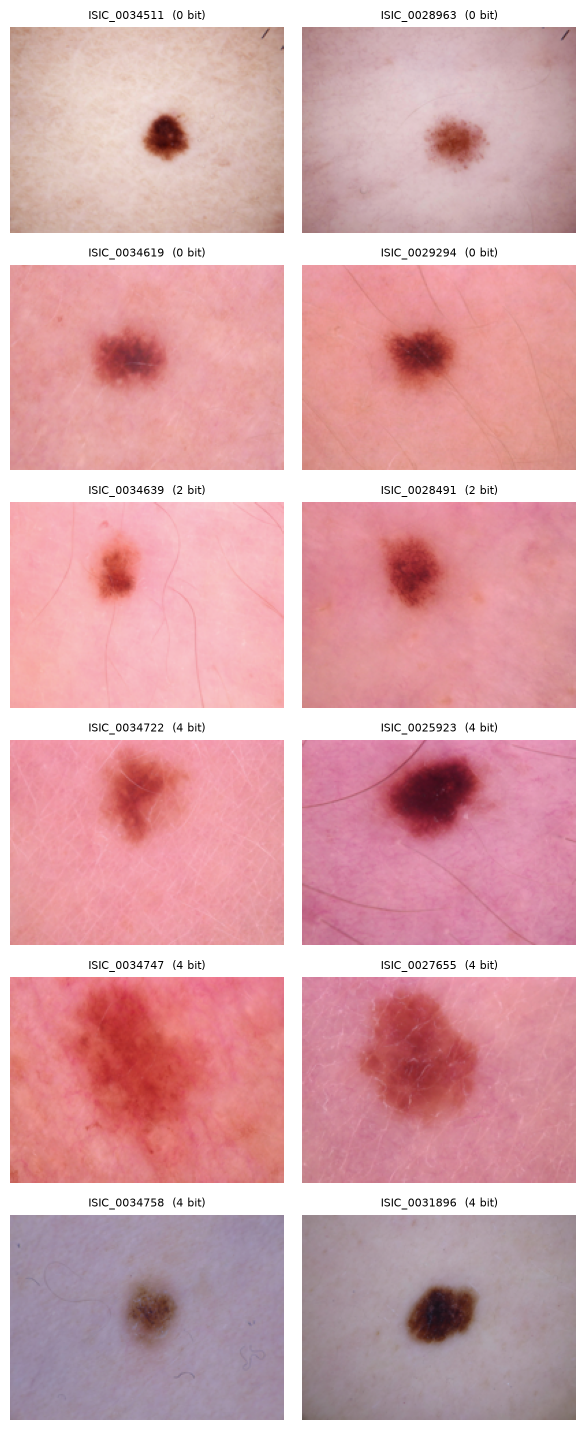

In [9]:
# Nhìn tận mắt tối đa 6 cặp. Nếu không trông giống nhau thì đó là trùng giả, bỏ qua.
if len(cap):
    duong = dict(zip(ds.image, ds.duong_dan))
    n = min(6, len(cap))
    fig, ax = plt.subplots(n, 2, figsize=(6, 2.4 * n), squeeze=False)
    for i in range(n):
        for j, k in enumerate(["anh", "anh_train_gan_nhat"]):
            ax[i, j].imshow(Image.open(duong[cap[k].iloc[i]]).resize((200, 150))); ax[i, j].axis("off")
            ax[i, j].set_title(f"{cap[k].iloc[i]}  ({cap.khoang_cach_bit.iloc[i]} bit)", fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("Không có cặp nào — tập test sạch theo tiêu chí này.")

## 8. Ghi danh mục

Một file, một dòng một ảnh, đủ cột cho mọi bước sau. Từ giờ không notebook nào tự đọc lại thư mục ảnh.

In [10]:
ds.drop(columns=["phash"]).to_csv(RA / "danh_muc.csv", index=False)
if len(cap): cap.to_csv(RA / "trung_test_train.csv", index=False)
print(f"Đã ghi {RA/'danh_muc.csv'}  ({len(ds)} dòng)")
print(ds.groupby("tap").size().to_string())

Đã ghi /home/deep/ham_fl/ketqua/danh_muc.csv  (11720 dòng)
tap
test           1512
training      10015
validation      193
